# 🌴 PalmaVision — Clasificación automática de madurez de racimos de palma de aceite

**Entrega 3 · Visión Artificial · Institución Universitaria ITM**  
**Docente:** Cristian Mateo Hernández González  
**Integrantes:** [Yerson Quesada] · [Ilson Cordoba ] · [Diego Tobon]

---

**Restricción técnica:** visión artificial *clásica*, sin Deep Learning (sin CNN).

**Pipeline:**
1. Extracción de características: HOG, LBP, GLCM y fusión (+ histograma de color HSV como extensión).
2. Normalización: Z-score (`StandardScaler`, ajustado **solo** con entrenamiento).
3. Clasificación: k-NN, SVM (RBF) y Random Forest.
4. Benchmark + métricas de negocio (costo del error de clasificación en COP).

## 1. El problema de negocio

En una planta extractora, el aceite que se obtiene depende de la **madurez del racimo de fruta fresca (RFF)** cuando se cosecha y se recibe:

- Racimos **inmaduros** → menor extracción de aceite (se pierde producto).
- Racimos **sobremaduros** → mayor acidez del aceite y fruto suelto que se cae (se pierde calidad y fruto).

Hoy esa clasificación la hace una persona **a ojo**, lo que es subjetivo, cansa y varía entre calificadores.

**Contexto Colombia** (Fedepalma, *Informe de Gestión 2025*): ~640 mil hectáreas sembradas en 21 departamentos, producción récord de 1,93 millones de toneladas de aceite crudo (+12 % frente a 2024) y un precio medio del aceite de palma de ~COP 4,4 millones por tonelada. Con volúmenes así, un pequeño error sistemático en el grado de madurez se traduce en mucho dinero.

> **Propuesta de valor:** un sistema de bajo costo, basado en visión clásica (rápido, interpretable, corre en un PC sin GPU) que clasifica la madurez del racimo a partir de una foto.

## 2. Datos

El notebook espera esta estructura (una carpeta por clase):

```
dataset/
 ├─ unripe/        (inmaduro)
 ├─ underripe/     (pintón / poco maduro)
 ├─ ripe/          (maduro)
 └─ overripe/      (sobremaduro)
```

Si el dataset trae carpetas `train/valid/test`, se pueden juntar en una sola por clase: el notebook hace su propia partición estratificada.

**Candidatos para descargar** (verificar licencia y formato antes de usar):
- *Outdoor oil palm fruit ripeness dataset* (Data in Brief, 2024, DOI 10.1016/j.dib.2024.110667): racimos clasificados en cinco clases (dañado, vacío, inmaduro, maduro y sobremaduro).
- Datasets en **Roboflow Universe** (buscar *palm fruit ripeness*): algunos traen 4 clases balanceadas (unripe, underripe, ripe, overripe). Si vienen en formato detección (cajas), exportar como *classification* o recortar las cajas.
- Kaggle: buscar *oil palm fruit ripeness*.

Todas las clases deben tener un número de imágenes parecido; si no, `F1 macro` y la matriz de confusión son más honestos que `accuracy`.

In [10]:
import os, time, warnings, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
#from google.colab import drive
drive.mount('/content/drive')
!unzip -q -o "/content/drive/MyDrive/Dataset_palma.zip" -d /content/dataset_palma

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q -o "/content/drive/MyDrive/Dataset_palma.zip" -d /content/dataset_palma

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# ----------------------------- CONFIGURACIÓN -----------------------------
DATA_DIR      = Path("/content/dataset_palma/Dataset/Images")      # carpeta con una subcarpeta por clase
FEATURES_DIR  = Path("features")     # aquí se guardan los .npz de características
MODELS_DIR    = Path("models")       # aquí se guarda el modelo final
IMG_SIZE      = (128, 128)           # tamaño al que se redimensionan todas las imágenes
MAX_POR_CLASE = 1000                 # tope de imágenes por clase (para controlar tiempos)
TEST_SIZE     = 0.30                 # 70 % entrenamiento / 30 % validación (estratificado)
EXT           = (".jpg", ".jpeg", ".png", ".bmp")

FEATURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

## 3. Carga y preprocesamiento
Se lee cada imagen, se pasa a RGB y se redimensiona. Los descriptores clásicos trabajan sobre imágenes de tamaño fijo; la normalización estadística se hace después, con Z-score sobre las características.

Imágenes por clase:
 0Immature          758
1PartiallyRipe    1000
2FullyRipe        1000
3OverRipe          665
4Decayed           411
Tensor de imágenes: (3834, 128, 128, 3)


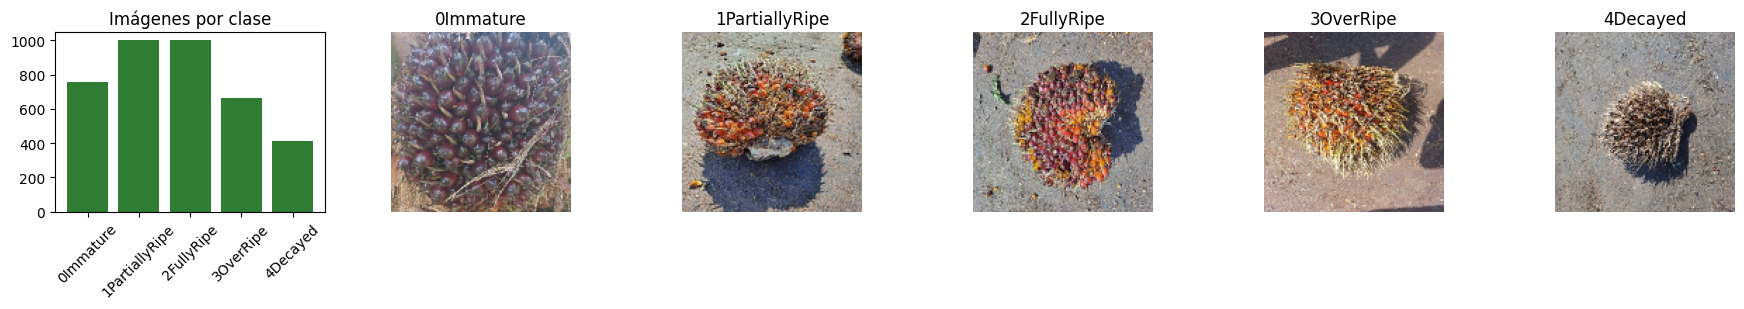

In [13]:
clases = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
assert len(clases) >= 2, f"Se esperaban subcarpetas por clase dentro de {DATA_DIR}"

def cargar_clase(carpeta, max_n):
    imgs = []
    for f in sorted(os.listdir(carpeta)):
        if not f.lower().endswith(EXT):
            continue
        img = cv2.imread(str(carpeta / f))
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        imgs.append(cv2.resize(img, IMG_SIZE))
        if len(imgs) >= max_n:
            break
    return imgs

imgs_all, y_all = [], []
for k, c in enumerate(clases):
    lote = cargar_clase(DATA_DIR / c, MAX_POR_CLASE)
    imgs_all += lote
    y_all += [k] * len(lote)

X_img = np.array(imgs_all, dtype=np.uint8)
y = np.array(y_all)

conteo = pd.Series(y).map(dict(enumerate(clases))).value_counts().reindex(clases)
print("Imágenes por clase:\n", conteo.to_string())
print("Tensor de imágenes:", X_img.shape)

# Distribución de clases + una muestra por clase
fig, axes = plt.subplots(1, len(clases) + 1, figsize=(3 * (len(clases) + 1), 3.2))
axes[0].bar(clases, conteo.values, color="#2e7d32")
axes[0].set_title("Imágenes por clase")
axes[0].tick_params(axis="x", rotation=45)
for k, c in enumerate(clases):
    axes[k + 1].imshow(X_img[np.where(y == k)[0][0]])
    axes[k + 1].set_title(c)
    axes[k + 1].axis("off")
plt.tight_layout()
plt.show()

In [14]:
idx = np.arange(len(y))
idx_tr, idx_va = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED, stratify=y)

X_tr_img, X_va_img = X_img[idx_tr], X_img[idx_va]
y_tr, y_va = y[idx_tr], y[idx_va]
print(f"Entrenamiento: {X_tr_img.shape} | Validación: {X_va_img.shape}")

Entrenamiento: (2683, 128, 128, 3) | Validación: (1151, 128, 128, 3)


## 4. Descriptores clásicos

| Descriptor | Qué captura | Por qué podría servir en un racimo de palma |
|---|---|---|
| **HOG** | Orientación de bordes / forma | La silueta del racimo y sus espinas; frutos sueltos y huecos en sobremaduros |
| **LBP** | Micro-textura local | Rugosidad de la superficie de los frutos |
| **GLCM** | Textura estadística (contraste, homogeneidad…) | Uniformidad del racimo a distintas escalas |
| **Color HSV** *(extensión)* | Distribución de tono, saturación y brillo | El **color** es la señal principal de madurez; HOG/LBP/GLCM trabajan en escala de grises y no lo ven |



In [15]:
def gris(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

def f_hog(img):
    return hog(gris(img), orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm="L2-Hys")

def f_lbp(img, P=8, R=1):
    lbp = local_binary_pattern(gris(img), P=P, R=R, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
    hist = hist.astype("float32")
    return hist / (hist.sum() + 1e-7)

def f_glcm(img, distances=(1, 3), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    g = (gris(img) // 4).astype(np.uint8)            # 64 niveles de gris
    glcm = graycomatrix(g, distances=list(distances), angles=list(angles),
                        levels=64, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    return np.concatenate([graycoprops(glcm, p).ravel() for p in props])

def f_color(img, bins=(16, 8, 8)):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    rangos = ([0, 180], [0, 256], [0, 256])
    partes = []
    for c in range(3):
        h = cv2.calcHist([hsv], [c], None, [bins[c]], rangos[c]).flatten()
        partes.append(h / (h.sum() + 1e-7))
    medias = hsv.reshape(-1, 3).mean(axis=0) / 255.0
    desv = hsv.reshape(-1, 3).std(axis=0) / 255.0
    return np.concatenate(partes + [medias, desv])

DESCRIPTORES = {"HOG": f_hog, "LBP": f_lbp, "GLCM": f_glcm, "COLOR_HSV": f_color}

def extraer(func, imgs):
    return np.array(Parallel(n_jobs=-1)(delayed(func)(im) for im in imgs))

In [16]:
raw = {}
for nombre, func in DESCRIPTORES.items():
    t0 = time.time()
    raw[nombre] = (extraer(func, X_tr_img), extraer(func, X_va_img))
    print(f"{nombre:10s} -> train {raw[nombre][0].shape} | {time.time()-t0:.1f} s")

HOG        -> train (2683, 8100) | 34.1 s
LBP        -> train (2683, 10) | 18.2 s
GLCM       -> train (2683, 48) | 15.9 s
COLOR_HSV  -> train (2683, 38) | 8.4 s


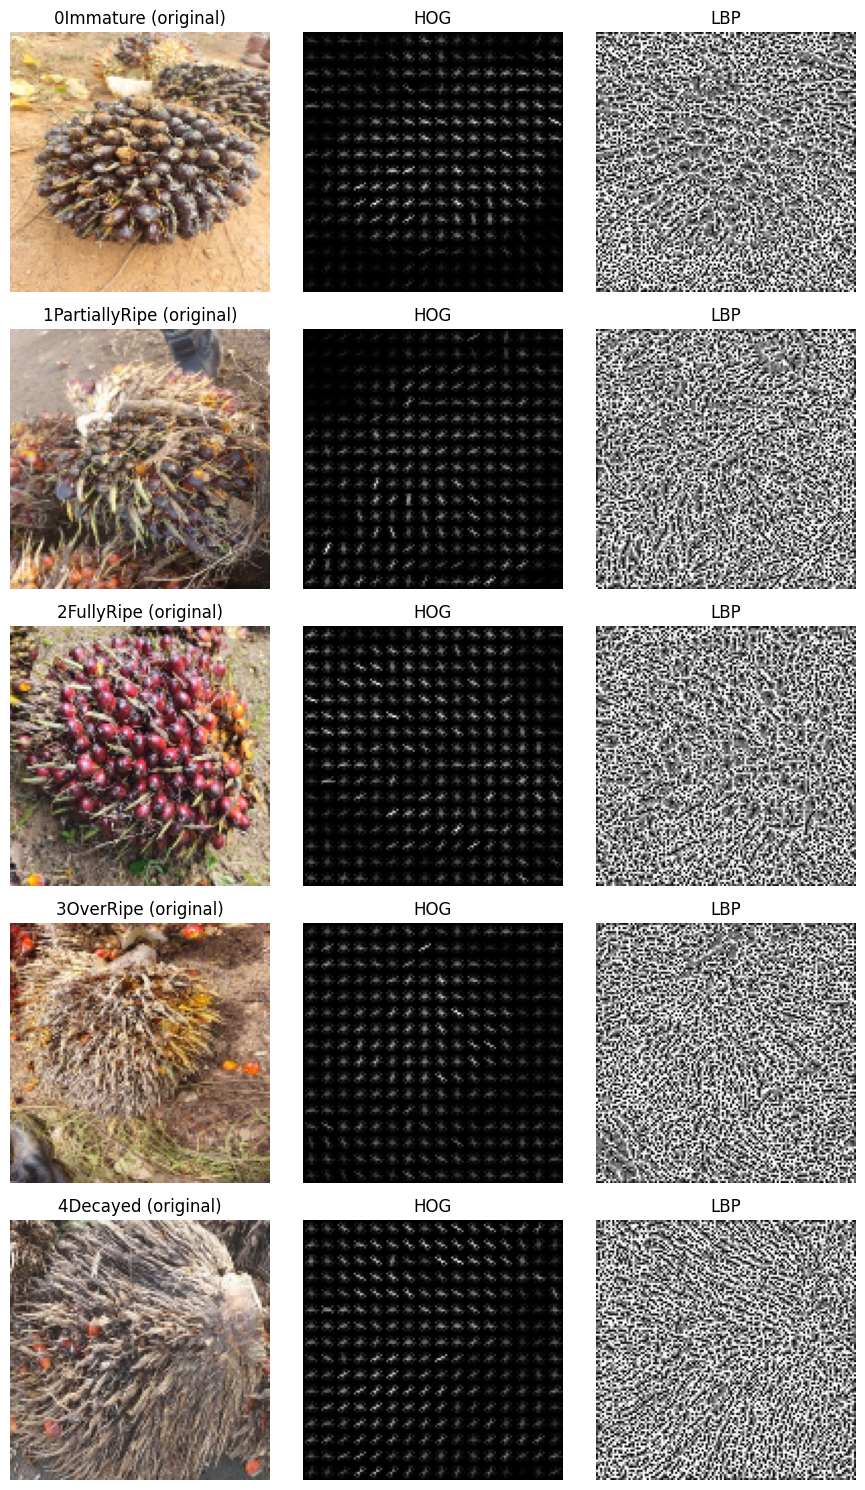

In [17]:
# Visualización de los descriptores: una imagen de validación por clase
fig, axes = plt.subplots(len(clases), 3, figsize=(9, 3 * len(clases)))
for r, c in enumerate(clases):
    i = np.where(y_va == r)[0][0]
    img = X_va_img[i]
    g = gris(img)
    _, hog_vis = hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp_vis = local_binary_pattern(g, 8, 1, method="uniform")
    axes[r, 0].imshow(img);                    axes[r, 0].set_title(f"{c} (original)")
    axes[r, 1].imshow(hog_vis, cmap="gray");   axes[r, 1].set_title("HOG")
    axes[r, 2].imshow(lbp_vis, cmap="gray");   axes[r, 2].set_title("LBP")
    for a in axes[r]:
        a.axis("off")
plt.tight_layout()
plt.show()

## 5. Normalización Z-score y fusión
Cada descriptor se normaliza con `StandardScaler`, **ajustado únicamente con entrenamiento** (para no filtrar información de validación). Normalizar cada descriptor por separado y concatenarlos equivale a normalizar el vector fusionado, porque Z-score actúa columna por columna.

In [18]:
scalers, esc = {}, {}
for nombre, (a, b) in raw.items():
    sc = StandardScaler().fit(a)
    scalers[nombre] = sc
    esc[nombre] = (sc.transform(a), sc.transform(b))

CONJUNTOS = {
    "HOG":                          ["HOG"],
    "LBP":                          ["LBP"],
    "GLCM":                         ["GLCM"],
    "FUSIÓN (HOG+LBP+GLCM)":        ["HOG", "LBP", "GLCM"],
    "COLOR HSV (extra)":            ["COLOR_HSV"],
    "FUSIÓN + COLOR (extra)":       ["HOG", "LBP", "GLCM", "COLOR_HSV"],
}

feats = {}
for nombre, bases in CONJUNTOS.items():
    Xtr = np.hstack([esc[b][0] for b in bases])
    Xva = np.hstack([esc[b][1] for b in bases])
    feats[nombre] = (Xtr, Xva)
    archivo = "features_" + nombre.split(" ")[0].lower().replace("ó", "o") + ("_color" if "COLOR" in nombre and "FUSI" in nombre else "") + ".npz"
    np.savez_compressed(FEATURES_DIR / archivo, X_train=Xtr, X_val=Xva, y_train=y_tr, y_val=y_va)

print({k: v[0].shape[1] for k, v in feats.items()})

{'HOG': 8100, 'LBP': 10, 'GLCM': 48, 'FUSIÓN (HOG+LBP+GLCM)': 8158, 'COLOR HSV (extra)': 38, 'FUSIÓN + COLOR (extra)': 8196}


## 6. Benchmark de clasificadores
Se usan los mismos hiperparámetros base del ejemplo del curso: k-NN (k=5), SVM RBF (C=1) y Random Forest (100 árboles). Como el problema tiene más de dos clases, las métricas de precisión, recall y F1 se promedian en modo **macro** (todas las clases pesan igual).

In [19]:
def crear_modelos():
    return {
        "k-NN (k=5)":    KNeighborsClassifier(n_neighbors=5, metric="euclidean"),
        "SVM (RBF)":     SVC(kernel="rbf", C=1.0, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    }

def ms_extraccion(func, imgs, n=30):
    t0 = time.perf_counter()
    for im in imgs[:n]:
        func(im)
    return (time.perf_counter() - t0) / min(n, len(imgs)) * 1000

T_EXT = {n: ms_extraccion(f, X_va_img) for n, f in DESCRIPTORES.items()}   # ms por imagen

resultados, entrenados = [], {}
for feat_name, (Xtr, Xva) in feats.items():
    lat_ext = sum(T_EXT[b] for b in CONJUNTOS[feat_name])
    for mod_name, modelo in crear_modelos().items():
        t0 = time.perf_counter()
        modelo.fit(Xtr, y_tr)
        t_fit = time.perf_counter() - t0

        t0 = time.perf_counter()
        y_pred = modelo.predict(Xva)
        t_clf = (time.perf_counter() - t0) / len(Xva) * 1000

        entrenados[(feat_name, mod_name)] = (modelo, y_pred)
        resultados.append({
            "Descriptor": feat_name, "Modelo": mod_name, "Dimensiones": Xtr.shape[1],
            "Accuracy":  accuracy_score(y_va, y_pred),
            "Precision": precision_score(y_va, y_pred, average="macro", zero_division=0),
            "Recall":    recall_score(y_va, y_pred, average="macro", zero_division=0),
            "F1-macro":  f1_score(y_va, y_pred, average="macro", zero_division=0),
            "Entrenamiento (s)": t_fit,
            "Latencia (ms/img)": lat_ext + t_clf,
        })

df_res = pd.DataFrame(resultados)
print("=" * 100)
print("TABLA DE BENCHMARK — madurez de racimos de palma de aceite")
print("=" * 100)
df_res.sort_values("F1-macro", ascending=False).round(3).reset_index(drop=True)

TABLA DE BENCHMARK — madurez de racimos de palma de aceite


,Descriptor,Modelo,Dimensiones,Accuracy,Precision,Recall,F1-macro,Entrenamiento (s),Latencia (ms/img)
0,COLOR HSV (extra),Random Forest,38,0.823,0.835,0.815,0.823,1.412,1.818
1,COLOR HSV (extra),SVM (RBF),38,0.805,0.814,0.798,0.805,0.437,1.926
2,COLOR HSV (extra),k-NN (k=5),38,0.799,0.807,0.795,0.800,0.001,1.825
3,FUSIÓN + COLOR (extra),Random Forest,8196,0.605,0.689,0.563,0.585,28.173,17.205
4,GLCM,Random Forest,48,0.532,0.539,0.499,0.509,2.856,3.806
5,LBP,SVM (RBF),10,0.503,0.503,0.492,0.495,0.337,3.672
6,LBP,Random Forest,10,0.478,0.477,0.472,0.474,0.868,3.563
7,GLCM,k-NN (k=5),48,0.487,0.487,0.453,0.456,0.001,3.779
8,FUSIÓN + COLOR (extra),SVM (RBF),8196,0.507,0.581,0.447,0.449,79.064,42.796
9,FUSIÓN (HOG+LBP+GLCM),Random Forest,8158,0.475,0.541,0.419,0.423,28.262,15.449


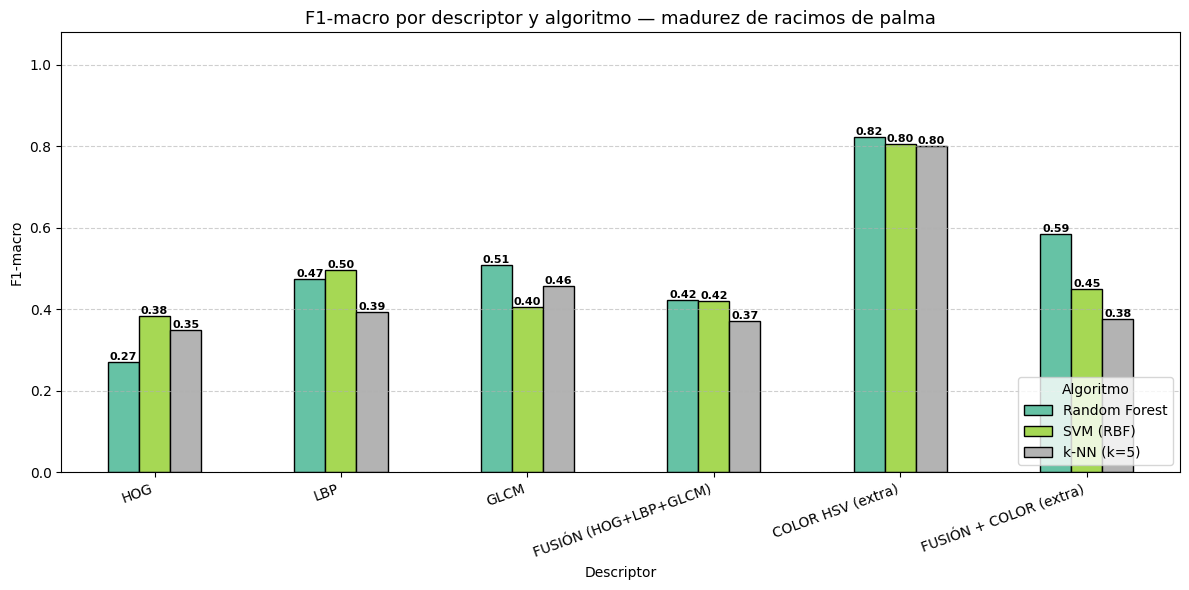

In [20]:
pivote = df_res.pivot(index="Descriptor", columns="Modelo", values="F1-macro").reindex(list(CONJUNTOS))
ax = pivote.plot(kind="bar", figsize=(12, 6), colormap="Set2", edgecolor="black")
plt.title("F1-macro por descriptor y algoritmo — madurez de racimos de palma", fontsize=13)
plt.ylabel("F1-macro"); plt.xlabel("Descriptor"); plt.ylim(0, 1.08)
plt.xticks(rotation=20, ha="right"); plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(title="Algoritmo", loc="lower right")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8, fontweight="bold")
plt.tight_layout()
plt.show()

In [21]:
# Lectura automática del benchmark (para el guion del video)
mejor = df_res.sort_values(["F1-macro", "Latencia (ms/img)"], ascending=[False, True]).iloc[0]
f1 = lambda d: df_res[df_res.Descriptor == d]["F1-macro"].max()

print(f"Mejor combinación: {mejor['Descriptor']} + {mejor['Modelo']}  "
      f"(F1-macro = {mejor['F1-macro']:.3f}, {mejor['Latencia (ms/img)']:.1f} ms/imagen)")
print(f"HOG: {f1('HOG'):.3f} | LBP: {f1('LBP'):.3f} | GLCM: {f1('GLCM'):.3f} | "
      f"Color HSV: {f1('COLOR HSV (extra)'):.3f} | Fusión: {f1('FUSIÓN (HOG+LBP+GLCM)'):.3f} | "
      f"Fusión+Color: {f1('FUSIÓN + COLOR (extra)'):.3f}")
mas_forma = "HOG" if f1("HOG") >= f1("GLCM") else "GLCM"
print(f"Entre HOG y GLCM, para este dataset gana: {mas_forma}.")

Mejor combinación: COLOR HSV (extra) + Random Forest  (F1-macro = 0.823, 1.8 ms/imagen)
HOG: 0.383 | LBP: 0.495 | GLCM: 0.509 | Color HSV: 0.823 | Fusión: 0.423 | Fusión+Color: 0.585
Entre HOG y GLCM, para este dataset gana: GLCM.


## 7. Mejor modelo: matriz de confusión y reporte por clase
La matriz de confusión muestra **qué errores comete** el sistema, y eso es lo que realmente cuesta dinero en la planta.

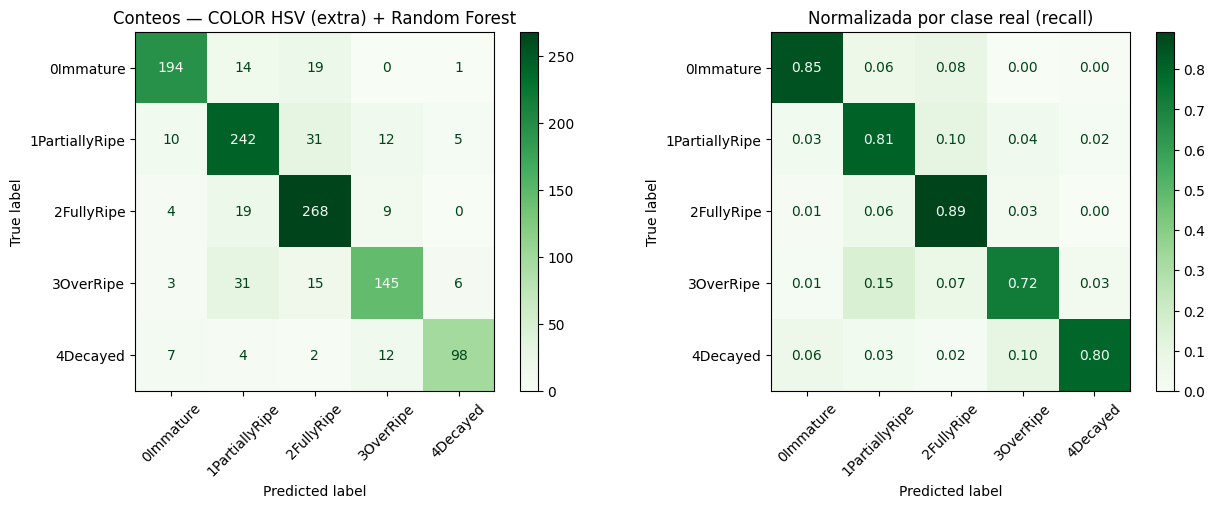

                precision    recall  f1-score   support

     0Immature       0.89      0.85      0.87       228
1PartiallyRipe       0.78      0.81      0.79       300
    2FullyRipe       0.80      0.89      0.84       300
     3OverRipe       0.81      0.72      0.77       200
      4Decayed       0.89      0.80      0.84       123

      accuracy                           0.82      1151
     macro avg       0.84      0.81      0.82      1151
  weighted avg       0.83      0.82      0.82      1151



In [22]:
mejor_desc, mejor_mod = mejor["Descriptor"], mejor["Modelo"]
modelo_final, y_pred_final = entrenados[(mejor_desc, mejor_mod)]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_va, y_pred_final, display_labels=clases, ax=ax[0],
                                        cmap="Greens", xticks_rotation=45)
ax[0].set_title(f"Conteos — {mejor_desc} + {mejor_mod}")
ConfusionMatrixDisplay.from_predictions(y_va, y_pred_final, display_labels=clases, ax=ax[1],
                                        cmap="Greens", normalize="true", values_format=".2f",
                                        xticks_rotation=45)
ax[1].set_title("Normalizada por clase real (recall)")
plt.tight_layout()
plt.show()

print(classification_report(y_va, y_pred_final, target_names=clases, zero_division=0))

## 8. Métricas de negocio
Los valores marcados como *supuesto* son **editables**: deben ajustarse con datos reales de la planta. El precio del aceite proviene de Fedepalma (promedio 2025).

**Lógica de costo:** equivocarse por un nivel de madurez no cuesta lo mismo que equivocarse por tres, y el error no es simétrico:
- Clasificar como **más maduro** de lo que es → se cosecha o recibe fruta inmadura → se pierde aceite.
- Clasificar como **menos maduro** de lo que es → se deja pasar fruta sobremadura → se pierde calidad (acidez) y fruto.

In [24]:
# ======================= SUPUESTOS DE NEGOCIO (EDITABLES) =======================
PRECIO_ACEITE_COP_TON  = 4_400_000   # Fedepalma: precio medio del aceite de palma 2025
PESO_RACIMO_KG         = 20.0        # SUPUESTO: peso medio de un racimo
PERDIDA_OER_PREMATURA  = 0.02        # SUPUESTO: fracción del peso que se pierde en aceite por nivel de inmadurez
PERDIDA_OER_TARDIA     = 0.015       # SUPUESTO: pérdida equivalente por nivel de sobremadurez no detectada
COSTO_OTRO_COP         = 5_000       # SUPUESTO: costo de confundir clases no ordenables (p. ej. dañado/vacío)
ERROR_CALIFICADOR      = 0.15        # SUPUESTO: tasa de error de la clasificación manual a ojo
RACIMOS_POR_DIA        = 5_000       # SUPUESTO: racimos que recibe/clasifica la planta por día
DIAS_OPERACION_ANIO    = 300         # SUPUESTO
INVERSION_INICIAL_COP  = 30_000_000  # SUPUESTO: cámara, iluminación, PC e instalación

# Orden de madurez (de menos a más maduro). Edita si tus clases se llaman distinto.
SINONIMOS = {"unripe": 0, "verde": 0, "inmaduro": 0, "underripe": 1, "pinton": 1, "pintón": 1,
             "ripe": 2, "maduro": 2, "overripe": 3, "sobremaduro": 3}
ORDINAL = {"0Immature": 0, "1PartiallyRipe": 1, "2FullyRipe": 2, "3OverRipe": 3, "4Decayed": None}
print("Orden de madurez detectado:", ORDINAL)
if all(v is None for v in ORDINAL.values()):
    print("⚠️ No se reconocieron los nombres de clase: edita ORDINAL manualmente.")

Orden de madurez detectado: {'0Immature': 0, '1PartiallyRipe': 1, '2FullyRipe': 2, '3OverRipe': 3, '4Decayed': None}


In [26]:
def costo_error(real, pred):
    if real == pred:
        return 0.0
    o_r, o_p = ORDINAL.get(real), ORDINAL.get(pred)
    if o_r is None or o_p is None:
        return float(COSTO_OTRO_COP)
    perdida = PERDIDA_OER_PREMATURA if o_p > o_r else PERDIDA_OER_TARDIA
    return abs(o_p - o_r) * PESO_RACIMO_KG * perdida / 1000 * PRECIO_ACEITE_COP_TON

k = len(clases)
C = np.array([[costo_error(clases[i], clases[j]) for j in range(k)] for i in range(k)])
print("Matriz de costo (COP por racimo mal clasificado; filas=real, columnas=predicho):")
print(pd.DataFrame(C, index=clases, columns=clases).round(0).astype(int).to_string())

def evaluar_negocio(y_real, y_pred):
    conf = confusion_matrix(y_real, y_pred, labels=range(k))
    costo_1000 = (conf * C).sum() / conf.sum() * 1000
    return costo_1000

costo_modelo_1000 = evaluar_negocio(y_va, y_pred_final)

fuera_diag = C[~np.eye(k, dtype=bool)]
costo_manual_1000 = 1000 * ERROR_CALIFICADOR * fuera_diag.mean()   # error manual repartido entre todos los tipos de error

ahorro_1000   = costo_manual_1000 - costo_modelo_1000
ahorro_anual  = ahorro_1000 / 1000 * RACIMOS_POR_DIA * DIAS_OPERACION_ANIO
payback_meses = INVERSION_INICIAL_COP / ahorro_anual * 12 if ahorro_anual > 0 else float("inf")
rapidez_img_s = 1000 / mejor["Latencia (ms/img)"]

print("\n" + "=" * 70)
print(f"Modelo elegido: {mejor_desc} + {mejor_mod}")
print(f"Accuracy {mejor['Accuracy']:.1%} | F1-macro {mejor['F1-macro']:.3f}")
print(f"Velocidad: {rapidez_img_s:.1f} imágenes/s en CPU")
print("-" * 70)
print(f"Costo del error por cada 1.000 racimos — calificación manual : COP {costo_manual_1000:,.0f}")
print(f"Costo del error por cada 1.000 racimos — PalmaVision        : COP {costo_modelo_1000:,.0f}")
print(f"Ahorro por cada 1.000 racimos                              : COP {ahorro_1000:,.0f}")
print(f"Ahorro anual proyectado ({RACIMOS_POR_DIA:,} racimos/día, {DIAS_OPERACION_ANIO} días)    : COP {ahorro_anual:,.0f}")
if ahorro_anual > 0:
    print(f"Recuperación de la inversión (payback)                     : {payback_meses:.1f} meses")
else:
    print("⚠️ Con estos supuestos el modelo no supera al calificador manual: revisa el modelo o los supuestos.")
print("=" * 70)

Matriz de costo (COP por racimo mal clasificado; filas=real, columnas=predicho):
                0Immature  1PartiallyRipe  2FullyRipe  3OverRipe  4Decayed
0Immature               0            1760        3520       5280      5000
1PartiallyRipe       1320               0        1760       3520      5000
2FullyRipe           2640            1320           0       1760      5000
3OverRipe            3960            2640        1320          0      5000
4Decayed             5000            5000        5000       5000         0

Modelo elegido: COLOR HSV (extra) + Random Forest
Accuracy 82.3% | F1-macro 0.823
Velocidad: 550.0 imágenes/s en CPU
----------------------------------------------------------------------
Costo del error por cada 1.000 racimos — calificación manual : COP 531,000
Costo del error por cada 1.000 racimos — PalmaVision        : COP 479,166
Ahorro por cada 1.000 racimos                              : COP 51,834
Ahorro anual proyectado (5,000 racimos/día, 300 días)    : 

## 9. Guardado del modelo y predicción sobre una imagen nueva
Se guarda todo lo necesario para usar el sistema en producción: el modelo, los escaladores Z-score y la configuración de descriptores.

In [27]:
bases_finales = CONJUNTOS[mejor_desc]
paquete = {"modelo": modelo_final, "scalers": {b: scalers[b] for b in bases_finales},
           "bases": bases_finales, "clases": clases, "img_size": IMG_SIZE}
joblib.dump(paquete, MODELS_DIR / "palmavision_modelo.joblib")

def predecir_array(img_rgb, paquete=paquete):
    img = cv2.resize(img_rgb, paquete["img_size"])
    partes = [paquete["scalers"][b].transform(DESCRIPTORES[b](img).reshape(1, -1)) for b in paquete["bases"]]
    pred = paquete["modelo"].predict(np.hstack(partes))[0]
    return paquete["clases"][int(pred)]

def predecir_racimo(ruta_imagen):
    img = cv2.cvtColor(cv2.imread(str(ruta_imagen)), cv2.COLOR_BGR2RGB)
    return predecir_array(img)

# Demostración con 3 imágenes de validación
for i in range(3):
    print(f"Real: {clases[y_va[i]]:12s} -> Predicción: {predecir_array(X_va_img[i])}")

Real: 4Decayed     -> Predicción: 4Decayed
Real: 4Decayed     -> Predicción: 4Decayed
Real: 1PartiallyRipe -> Predicción: 4Decayed


## 10. Conclusiones (completar con los resultados reales de la ejecución)

1. **Mejor combinación:** _[COLOR HSV (extra) + Random Forest]_ con F1-macro de _[0.823	]_.
2. **¿HOG o GLCM?** _[

HOG fue el peor descriptor: F1 entre 0,27 y 0,38.
GLCM quedó por encima de HOG, con hasta 0,51, y LBP llegó a 0,50.
Color HSV ganó por mucho: 0,80 a 0,82 con los tres clasificadores. Pasa de 0,5 a 0,8, una diferencia demasiado grande para ser casualidad.
Las diferencias entre modelos dentro de un mismo descriptor, como 0,80 contra 0,82, sí pueden ser ruido. Lo sólido es la brecha entre descriptores.

Por qué ocurre:

HOG describe bordes y forma. La forma de un racimo casi no cambia entre inmaduro y maduro: lo que cambia es el color de los frutos. Además HOG se confunde con el fondo y las espinas.
GLCM describe qué tan uniforme o rugosa es la textura, y eso ayuda un poco, por ejemplo con racimos sobremaduros o podridos, pero sigue trabajando en escala de grises.
Color HSV mide directamente la señal de madurez: el tono pasa de oscuro a naranja y rojo.]_.

3. **Errores más costosos:** _[Con color HSV + Random Forest, el modelo acierta cerca del 82 %. Los errores más costosos son clasificar racimos sobremaduros como menos maduros (recall de 0,72, la clase más débil), lo que deja pasar fruta con alta acidez, y clasificar racimos inmaduros como maduros, que implica cosecha prematura y pérdida de aceite. La mayoría de los errores son entre niveles vecinos, pero hay confusiones que saltan un nivel que conviene investigar.]_.
4. **Limitaciones honestas:** dataset limitado, condiciones de luz, fondo, y que los supuestos de negocio deben validarse con una planta real.
5. **Siguientes pasos:** validación con datos de una extractora colombiana, control de iluminación en la línea, y cámara en la báscula de recepción.